# Giải Phẫu Mô Hình Stage 1 (`Stage1BaselineD1`) — Trích Xuất Đặc Trưng & Ra Quyết Định

Notebook này nạp trực tiếp bộ trọng số đã huấn luyện **`checkpoints/stage1_d1_best.pt`** (`Run S1-01`, Best Epoch = `11`, `0%` pretrained) trên tập **`valid` sạch (`clean Group Split`)** để quan sát trực quan toàn bộ quá trình bên trong mạng CNN:

1. **Cấu trúc các tầng tích chập & Vùng tiếp nhận (Receptive Field):** Từ ảnh đầu vào `416×416` giảm mẫu dần xuống lưới `26×26` (`stride = 16 px`).
2. **Bản đồ đặc trưng (Feature Maps) qua 5 cột mốc không gian:** Cách mạng lọc bỏ gợn nước/ánh nắng và gom tín hiệu cơ thể người về tâm ô lưới.
3. **Các kênh bộ lọc chuyên biệt ở `head_refine` (`128` kênh, `dilation = 2`):** Mỗi kênh phản ứng với một đặc trưng thị giác khác nhau (vùng da/đầu, bọt nước quanh người, ức chế nền thành bể).
4. **Giải phẫu 4 bước ra quyết định của Detection Head:**
   - Bản đồ nhiệt xác suất có người $\sigma(\text{logit}_{\text{obj}})$ trên lưới `26×26`.
   - Chùm hộp ứng viên thô trước lọc trùng (*Pre-NMS*: nhiều ô cạnh nhau cùng chỉ vào 1 người).
   - Khử cực đại cục bộ bằng **Standard NMS** (`IoU = 0.5`) so với **Gaussian Soft-NMS** (`σ = 0.5`).
   - Đối chiếu với nhãn thật (**GT — Xanh lá**) để hiểu cả ca bắt trúng lẫn ca lệch biên `0.25 ≤ IoU < 0.50`.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import torch

# Tự động thêm thư mục gốc SafePool vào sys.path dù mở Notebook từ thư mục con
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.datasets.stage1_dataset import Stage1Dataset
from src.engine.trainer import get_device
from src.metrics import box_iou_xyxy
from src.models.stage1_baseline import Stage1BaselineD1, decode_stage1_outputs
from src.utils.edge_profiler import targets_yolo_to_xyxy

device = get_device("auto")
ckpt_path = PROJECT_ROOT / "checkpoints" / "stage1_d1_best.pt"
assert ckpt_path.is_file(), f"Không tìm thấy trọng số tại: {ckpt_path}"

# Nạp mô hình & trọng số tốt nhất từ lượt chạy S1-01 (tương thích cả MPS / CUDA / CPU)
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model = Stage1BaselineD1().to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

valid_ds = Stage1Dataset(manifest_path=PROJECT_ROOT / "data/stage1/manifest.json", split="valid")

print(f"Thiết bị suy luận : {device}")
print(f"Checkpoint nạp từ : {ckpt_path.relative_to(PROJECT_ROOT)} (Best Epoch = {ckpt['epoch']})")
print(f"Số ảnh tập valid  : {len(valid_ds):,} ảnh (clean Group Split — 0% rò rỉ video nguồn)")
print("-" * 78)
print(f"{'Tầng mạng':<26} | {'Kích thước Tensor':<20} | {'Stride':<8} | {'Vai trò trích đặc trưng'}")
print("-" * 78)
dummy = torch.zeros((1, 3, 416, 416), device=device)
with torch.no_grad():
    x = dummy
    roles = [
        "Biên cạnh sắc nét, gợn sóng, viền cơ thể",
        "Kết cấu cục bộ (mảng da, bọt trắng, chói nắng)",
        "Đặc trưng trung gian mức bộ phận cơ thể",
        "Tinh lọc bộ phận, giảm nhiễu nền mặt nước",
        "Đặc trưng ngữ nghĩa mức toàn thân người bơi",
        "Tăng cường tương phản người vs nền hồ bơi",
        "Dilated Conv (d=2): mở rộng vùng nhìn ~143 px",
    ]
    for i, block in enumerate(model.backbone):
        x = block(x)
        st = 416 // x.shape[-1]
        print(f"backbone[{i}] ConvBNSiLU     | {str(tuple(x.shape)):<20} | {st:<8} | {roles[i]}")
    x = model.head_refine(x)
    print(f"head_refine (dilation=2)   | {str(tuple(x.shape)):<20} | {416 // x.shape[-1]:<8} | Tinh lọc cuối (RF ~207 px) trước khi đoán")
    out = model.head_out(x)
    print(f"head_out (Conv 1x1 -> 5)   | {str(tuple(out.shape)):<20} | {416 // out.shape[-1]:<8} | [obj_logit, tx, ty, tw, th] cho 676 ô lưới")

Thiết bị suy luận : mps
Checkpoint nạp từ : checkpoints/stage1_d1_best.pt (Best Epoch = 11)
Số ảnh tập valid  : 1,855 ảnh (clean Group Split — 0% rò rỉ video nguồn)
------------------------------------------------------------------------------
Tầng mạng                  | Kích thước Tensor    | Stride   | Vai trò trích đặc trưng
------------------------------------------------------------------------------
backbone[0] ConvBNSiLU     | (1, 32, 208, 208)    | 2        | Biên cạnh sắc nét, gợn sóng, viền cơ thể
backbone[1] ConvBNSiLU     | (1, 64, 104, 104)    | 4        | Kết cấu cục bộ (mảng da, bọt trắng, chói nắng)
backbone[2] ConvBNSiLU     | (1, 128, 52, 52)     | 8        | Đặc trưng trung gian mức bộ phận cơ thể
backbone[3] ConvBNSiLU     | (1, 128, 52, 52)     | 8        | Tinh lọc bộ phận, giảm nhiễu nền mặt nước
backbone[4] ConvBNSiLU     | (1, 160, 26, 26)     | 16       | Đặc trưng ngữ nghĩa mức toàn thân người bơi
backbone[5] ConvBNSiLU     | (1, 160, 26, 26)     | 16       

## 1. Tự Động Chọn 4 Mẫu Điển Hình Trên Tập `valid` Sạch

Để quan sát khách quan cách mạng hoạt động trong nhiều bối cảnh thực tế khác nhau, ta quét nhanh tập `valid` để lấy 4 tình huống đại diện:
1. **Mẫu Chuẩn Xác (`Clean Hit`):** 1–2 người bơi rõ ràng, mạng bắt khít khung bao (`IoU > 0.80`) với điểm tự tin cao.
2. **Mẫu Đông Người (`Crowded Pool`):** Hồ bơi đông người (`≥ 5` người) — kiểm tra khả năng tách tâm trên lưới `26×26` và đối chiếu `NMS` vs `Soft-NMS`.
3. **Mẫu Mục Tiêu Nhỏ (`Small Box < 32×32 px`):** Người ở xa đầu bể — theo dõi xem tín hiệu nhỏ biến đổi thế nào khi đi từ tầng nông `208×208` xuống `26×26`.
4. **Mẫu Lệch Biên (`Poor Localization: 0.30 ≤ IoU < 0.50`):** Minh họa nhóm lỗi chiếm `59.3%` tổng FN của `D1` — mạng **đã phát hiện đúng vị trí có người**, nhưng khung bao bị co/giãn lệch nhẹ dưới ngưỡng `0.50`.

In [2]:
def find_representative_samples(dataset: Stage1Dataset, max_scan: int = 500) -> dict:
    chosen = {}
    scan_n = min(len(dataset), max_scan)

    for idx in range(scan_n):
        img_t, tgt_yolo = dataset[idx]
        gt_boxes = targets_yolo_to_xyxy([tgt_yolo])[0]["boxes"]
        if len(gt_boxes) == 0:
            continue

        with torch.no_grad():
            raw = model(img_t.unsqueeze(0).to(device))
            dec_nms = decode_stage1_outputs(raw, score_thr=0.25, nms_type="nms")[0]
            dec_soft = decode_stage1_outputs(raw, score_thr=0.25, nms_type="soft_nms")[0]

        pb, ps = dec_nms["boxes"], dec_nms["scores"]
        ious = box_iou_xyxy(pb, gt_boxes) if len(pb) else np.zeros((0, len(gt_boxes)))

        # Kích thước pixel thực tế của từng GT
        w_px = (gt_boxes[:, 2] - gt_boxes[:, 0]) * 416.0
        h_px = (gt_boxes[:, 3] - gt_boxes[:, 1]) * 416.0
        areas_px = w_px * h_px

        # 1. Clean Hit: 1-2 người, khớp 1-1 gọn gàng với IoU >= 0.80 và score >= 0.75
        if "clean_hit" not in chosen and 1 <= len(gt_boxes) <= 2 and len(pb) == len(gt_boxes):
            best_per_gt = ious.max(axis=0)
            if (best_per_gt >= 0.80).all() and (ps >= 0.75).all():
                chosen["clean_hit"] = idx

        # 2. Crowded Pool: >= 6 người, phát hiện được phần lớn người bơi
        if "crowded" not in chosen and len(gt_boxes) >= 6 and len(pb) >= 5:
            matched_cnt = int((ious.max(axis=0) >= 0.50).sum()) if len(pb) else 0
            if matched_cnt >= 5 and len(dec_soft["boxes"]) >= len(pb):
                chosen["crowded"] = idx

        # 3. Small Target: có ít nhất 1 người diện tích < 32x32 px (1024 px^2) và mạng bắt trúng (IoU >= 0.55)
        if "small_target" not in chosen and (areas_px < 900.0).any() and len(pb) > 0:
            small_mask = areas_px < 900.0
            small_ious = ious[:, small_mask].max(axis=0)
            if (small_ious >= 0.55).any() and len(gt_boxes) <= 4:
                chosen["small_target"] = idx

        # 4. Poor Localization: 1-2 người, mạng có dự đoán score >= 0.35 nhưng IoU rơi vào [0.35, 0.47]
        if "poor_loc" not in chosen and 1 <= len(gt_boxes) <= 2 and len(pb) >= 1:
            best_per_gt = ious.max(axis=0)
            if ((best_per_gt >= 0.35) & (best_per_gt <= 0.47)).any() and ps.max() >= 0.40:
                chosen["poor_loc"] = idx

        if len(chosen) == 4:
            break

    ordered_keys = ["clean_hit", "crowded", "small_target", "poor_loc"]
    return {k: chosen[k] for k in ordered_keys if k in chosen}


SAMPLE_CASES = find_representative_samples(valid_ds, max_scan=600)
CASE_LABELS = {
    "clean_hit": "Mẫu 1: Bắt chuẩn xác (Clean Hit)",
    "crowded": "Mẫu 2: Bể đông người (Crowded >= 6)",
    "small_target": "Mẫu 3: Mục tiêu nhỏ ở xa (< 32x32 px)",
    "poor_loc": "Mẫu 4: Ca lệch biên (0.35 <= IoU < 0.50)",
}

for key, idx in SAMPLE_CASES.items():
    entry = valid_ds.entries[idx]
    _, tgt = valid_ds[idx]
    print(f"{CASE_LABELS[key]:<42} -> valid[{idx:3d}] | Số GT = {len(tgt)} | File: {Path(entry['image_path']).name}")

Mẫu 1: Bắt chuẩn xác (Clean Hit)           -> valid[ 87] | Số GT = 1 | File: image1981_jpg.rf.195526a7830e1cf971d4dbaaf8f58233.jpg
Mẫu 2: Bể đông người (Crowded >= 6)        -> valid[  4] | Số GT = 22 | File: 130338_jpg.rf.d5197ef9189141a94d3e1fd68304361b.jpg
Mẫu 3: Mục tiêu nhỏ ở xa (< 32x32 px)      -> valid[ 82] | Số GT = 1 | File: image1014_jpg.rf.6debae79ab6289553b68d437587094d7.jpg
Mẫu 4: Ca lệch biên (0.35 <= IoU < 0.50)   -> valid[ 14] | Số GT = 2 | File: 167_jpg.rf.b9ea39ef1ab5e199584f0580cfc92d71.jpg

## 2. Hành Trình Trích Xuất Đặc Trưng Từ Tầng Nông Đến Tầng Sâu (`416 → 208 → 104 → 52 → 26`)

Ta gắn **Forward Hook** vào 5 tầng tiêu biểu của `Stage1BaselineD1` để xem mạng "nhìn" bức ảnh bể bơi thay đổi dần như thế nào:
- **Các tầng đầu (`208×208`, `104×104`):** Phản ứng mạnh với mọi biên độ tương phản (cả người bơi, thành bể, dây phao lẫn sóng nước).
- **Tầng giữa (`52×52`):** Bắt đầu gom cụm hình dáng người và làm dịu các gợn sóng nhỏ.
- **Tầng sâu (`backbone[6]` & `head_refine` `26×26`):** Nhờ tích chập giãn nở `dilation=2` (`RF ≈ 207×207 px`), nền nước xung quanh bị dập tắt (màu tối), năng lượng kích hoạt hội tụ thành **các điểm sáng đúng tại tâm người bơi**, dẫn thẳng tới **Bản đồ xác suất Objectness $\sigma(\text{logit}_0)$** ở cột cuối cùng!

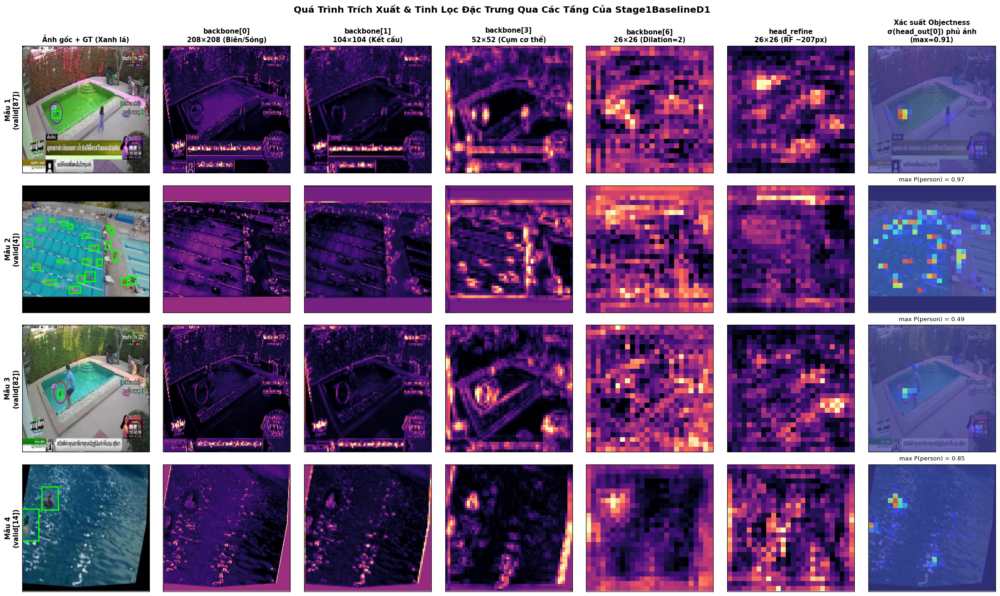

In [3]:
def extract_features_and_raw_output(img_tensor: torch.Tensor):
    """Chạy 1 ảnh qua mạng và thu thập bản đồ đặc trưng ở 5 tầng + tensor đầu ra [5, 26, 26]."""
    captured = {}
    hook_layers = {
        "L0_208x208": model.backbone[0],
        "L1_104x104": model.backbone[1],
        "L3_52x52": model.backbone[3],
        "L6_26x26_dilated": model.backbone[6],
        "HeadRefine_26x26": model.head_refine,
    }
    handles = []
    for name, layer in hook_layers.items():
        def _make_hook(layer_name: str):
            def _hook(_m, _inp, out):
                captured[layer_name] = out.detach().cpu()[0]
            return _hook

        handles.append(layer.register_forward_hook(_make_hook(name)))

    try:
        with torch.no_grad():
            raw_out = model(img_tensor.unsqueeze(0).to(device)).detach().cpu()[0]
    finally:
        for h in handles:
            h.remove()

    return captured, raw_out


def normalize_map(fmap_2d: np.ndarray) -> np.ndarray:
    lo, hi = float(np.percentile(fmap_2d, 2)), float(np.percentile(fmap_2d, 99.5))
    return np.clip((fmap_2d - lo) / (hi - lo + 1e-6), 0.0, 1.0)


fig, axes = plt.subplots(len(SAMPLE_CASES), 7, figsize=(21, 3.1 * len(SAMPLE_CASES)), constrained_layout=True)
col_titles = [
    "Ảnh gốc + GT (Xanh lá)",
    "backbone[0]\n208×208 (Biên/Sóng)",
    "backbone[1]\n104×104 (Kết cấu)",
    "backbone[3]\n52×52 (Cụm cơ thể)",
    "backbone[6]\n26×26 (Dilation=2)",
    "head_refine\n26×26 (RF ~207px)",
    "Xác suất Objectness\nσ(head_out[0]) phủ ảnh",
]

for row_idx, (case_key, ds_idx) in enumerate(SAMPLE_CASES.items()):
    img_t, tgt_yolo = valid_ds[ds_idx]
    img_np = img_t.permute(1, 2, 0).numpy()
    gt_boxes = targets_yolo_to_xyxy([tgt_yolo])[0]["boxes"]
    feats, raw_out = extract_features_and_raw_output(img_t)
    obj_prob = torch.sigmoid(raw_out[0]).numpy()  # [26, 26]

    # Cột 0: Ảnh gốc + GT
    ax0 = axes[row_idx, 0]
    ax0.imshow(img_np)
    for x1, y1, x2, y2 in gt_boxes:
        rect = patches.Rectangle(
            (x1 * 416, y1 * 416), (x2 - x1) * 416, (y2 - y1) * 416,
            linewidth=2.0, edgecolor="lime", facecolor="none"
        )
        ax0.add_patch(rect)
    ax0.set_ylabel(CASE_LABELS[case_key].split(":")[0] + f"\n(valid[{ds_idx}])", fontsize=10, fontweight="bold")

    # Cột 1..5: Trung bình năng lượng kích hoạt L2 qua các kênh ở từng tầng
    feat_keys = ["L0_208x208", "L1_104x104", "L3_52x52", "L6_26x26_dilated", "HeadRefine_26x26"]
    for c_offset, fk in enumerate(feat_keys, start=1):
        ax = axes[row_idx, c_offset]
        fmap = feats[fk]  # [C, H, W]
        energy = torch.linalg.vector_norm(fmap, ord=2, dim=0).numpy()
        ax.imshow(normalize_map(energy), cmap="magma")

    # Cột 6: Bản đồ xác suất Objectness phủ lên ảnh gốc
    ax6 = axes[row_idx, 6]
    ax6.imshow(img_np, alpha=0.60)
    im = ax6.imshow(
        obj_prob, cmap="jet", vmin=0.0, vmax=1.0, alpha=0.55,
        extent=(0, 416, 416, 0), interpolation="nearest"
    )
    ax6.set_title(f"max P(person) = {obj_prob.max():.2f}", fontsize=9)

    for col_idx in range(7):
        axes[row_idx, col_idx].set_xticks([])
        axes[row_idx, col_idx].set_yticks([])
        if row_idx == 0 and col_idx < 6:
            axes[row_idx, col_idx].set_title(col_titles[col_idx], fontsize=10, fontweight="bold")
        elif row_idx == 0 and col_idx == 6:
            axes[row_idx, col_idx].set_title(col_titles[col_idx] + f"\n(max={obj_prob.max():.2f})", fontsize=10, fontweight="bold")

plt.suptitle("Quá Trình Trích Xuất & Tinh Lọc Đặc Trưng Qua Các Tầng Của Stage1BaselineD1", fontsize=14, fontweight="bold")
plt.show()

## 3. Soi Bên Trong `head_refine`: Các Kênh Bộ Lọc Học Chuyên Biệt Gì?

Tầng `head_refine` có `128` kênh đặc trưng kích thước `26×26` đặt ngay trước lớp quyết định `Conv 1×1 (128 → 5)`.
Nhân trọng số `head_out.weight[0]` (`[128, 1, 1]`) với `head_refine` cho ta biết **kênh nào đóng góp dương mạnh nhất để khẳng định "có người"** và **kênh nào đóng góp âm để ức chế nền hồ bơi**:

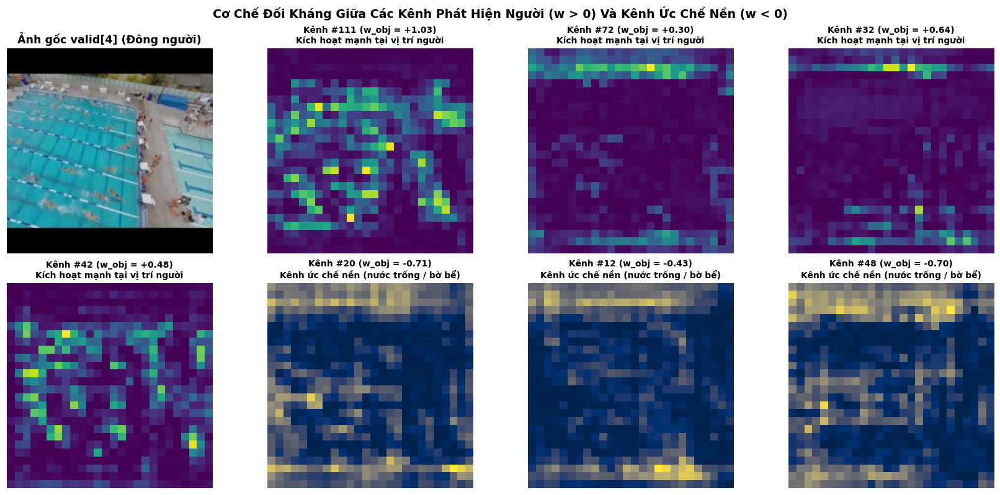

In [4]:
# Phân tích đóng góp của 128 kênh head_refine vào logit Objectness trên Mẫu Đông Người
crowd_idx = SAMPLE_CASES["crowded"]
img_crowd, tgt_crowd = valid_ds[crowd_idx]
feats_crowd, raw_crowd = extract_features_and_raw_output(img_crowd)

head_feat = feats_crowd["HeadRefine_26x26"]                     # [128, 26, 26]
obj_weights = model.head_out.weight.detach().cpu()[0, :, 0, 0]  # [128] trọng số nối sang obj_logit

# Đóng góp thực tế của kênh k tại các ô có điểm cao: w_k * activation_k
weighted_contrib = obj_weights[:, None, None] * head_feat        # [128, 26, 26]
pos_channel_scores = weighted_contrib.amax(dim=(1, 2))
neg_channel_scores = weighted_contrib.amin(dim=(1, 2))

top_pos_channels = torch.topk(pos_channel_scores, k=4).indices.tolist()
top_neg_channels = torch.topk(-neg_channel_scores, k=3).indices.tolist()

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), constrained_layout=True)

# Ô đầu: Ảnh gốc
axes[0, 0].imshow(img_crowd.permute(1, 2, 0).numpy())
axes[0, 0].set_title(f"Ảnh gốc valid[{crowd_idx}] (Đông người)", fontweight="bold")
axes[0, 0].axis("off")

# 4 kênh kích thích dương mạnh nhất (bật sáng khi gặp người)
for idx_plot, ch in enumerate(top_pos_channels[:3], start=1):
    ax = axes[0, idx_plot]
    ax.imshow(head_feat[ch].numpy(), cmap="viridis")
    ax.set_title(f"Kênh #{ch} (w_obj = +{obj_weights[ch]:.2f})\nKích hoạt mạnh tại vị trí người", fontsize=9.5, fontweight="bold")
    ax.axis("off")

ax_p4 = axes[1, 0]
ch4 = top_pos_channels[3]
ax_p4.imshow(head_feat[ch4].numpy(), cmap="viridis")
ax_p4.set_title(f"Kênh #{ch4} (w_obj = +{obj_weights[ch4]:.2f})\nKích hoạt mạnh tại vị trí người", fontsize=9.5, fontweight="bold")
ax_p4.axis("off")

# 3 kênh ức chế âm mạnh nhất (bật sáng ở mặt nước trống / thành bể -> trừ điểm obj_logit)
for idx_plot, ch in enumerate(top_neg_channels, start=1):
    ax = axes[1, idx_plot]
    ax.imshow(head_feat[ch].numpy(), cmap="cividis")
    ax.set_title(f"Kênh #{ch} (w_obj = {obj_weights[ch]:.2f})\nKênh ức chế nền (nước trống / bờ bể)", fontsize=9.5, fontweight="bold")
    ax.axis("off")

plt.suptitle("Cơ Chế Đối Kháng Giữa Các Kênh Phát Hiện Người (w > 0) Và Kênh Ức Chế Nền (w < 0)", fontsize=13, fontweight="bold")
plt.show()

## 4. Giải Phẫu Từng Bước Ra Quyết Định: Từ Lưới `26×26` $\to$ Pre-NMS $\to$ NMS vs Soft-NMS

Tại mỗi ô lưới $(g_x, g_y) \in \{0..25\}^2$, lớp `head_out` xuất 5 giá trị `[obj_logit, raw_tx, raw_ty, raw_tw, raw_th]` và giải mã bằng **Bounded Sigmoid**:
- Xác suất có người: $p = \sigma(\text{obj\_logit})$
- Tâm hộp chuẩn hóa: $c_x = \frac{g_x + \sigma(\text{raw\_tx})}{26}, \quad c_y = \frac{g_y + \sigma(\text{raw\_ty})}{26}$
- Rộng & cao chuẩn hóa: $w = \sigma(\text{raw\_tw}), \quad h = \sigma(\text{raw\_th})$

Hình dưới đây cho thấy **vì sao bắt buộc phải có bước NMS / Soft-NMS**: trước khi lọc trùng (*Cột 2*), quanh mỗi người bơi có tới **4–8 ô lưới lân cận cùng phát hiện và vẽ chồng hộp lên nhau**!

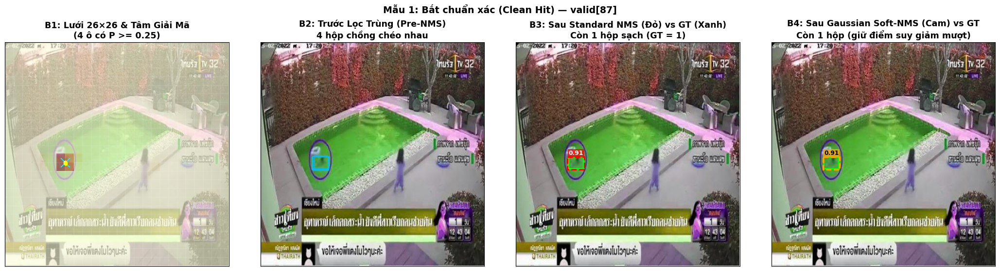

Bảng giải trình quyết định của mạng trên valid[87] (Standard NMS, score_thr=0.25):
  #Box   | Score   | Tọa độ Pixel [x1, y1, x2, y2]  | IoU cao nhất với GT  | Phân loại quyết định
  --------------------------------------------------------------------------------------------
  #0     | 0.907   | [ 95.8, 213.5, 126.7, 237.0]   | 0.811 (GT #0)        | TRUE POSITIVE (Khớp GT #0)

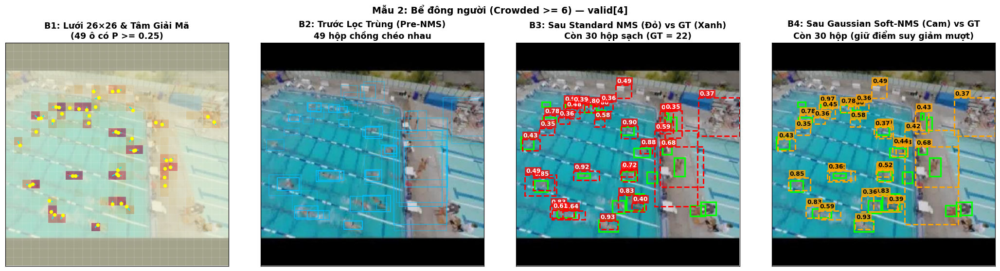

Bảng giải trình quyết định của mạng trên valid[4] (Standard NMS, score_thr=0.25):
  #Box   | Score   | Tọa độ Pixel [x1, y1, x2, y2]  | IoU cao nhất với GT  | Phân loại quyết định
  --------------------------------------------------------------------------------------------
  #0     | 0.973   | [ 88.2, 112.4, 112.5, 128.5]   | 0.192 (GT #15)       | FALSE POSITIVE (Báo nhầm vùng nền/bọt sóng)
  #1     | 0.928   | [155.0, 332.5, 189.3, 347.3]   | 0.633 (GT #6)        | TRUE POSITIVE (Khớp GT #6)
  #2     | 0.916   | [107.0, 239.0, 154.9, 256.6]   | 0.223 (GT #7)        | FALSE POSITIVE (Báo nhầm vùng nền/bọt sóng)
  #3     | 0.902   | [195.1, 155.6, 226.0, 178.6]   | 0.487 (GT #12)       | LỆCH BIÊN / DƯ HỘP quanh GT #12 (0.25<=IoU<0.5)
  #4     | 0.883   | [230.8, 193.1, 253.3, 206.6]   | 0.294 (GT #11)       | LỆCH BIÊN / DƯ HỘP quanh GT #11 (0.25<=IoU<0.5)
  #5     | 0.865   | [193.8, 238.4, 221.1, 249.5]   | 0.444 (GT #19)       | LỆCH BIÊN / DƯ HỘP quanh GT #19 (0.25<=IoU<0.5)
  #6

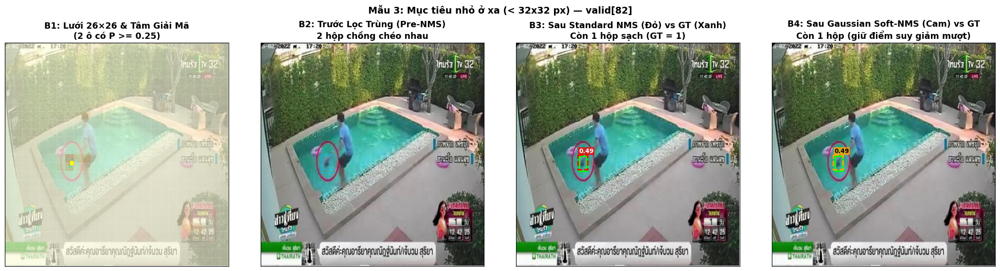

Bảng giải trình quyết định của mạng trên valid[82] (Standard NMS, score_thr=0.25):
  #Box   | Score   | Tọa độ Pixel [x1, y1, x2, y2]  | IoU cao nhất với GT  | Phân loại quyết định
  --------------------------------------------------------------------------------------------
  #0     | 0.488   | [114.4, 208.8, 132.5, 236.1]   | 0.631 (GT #0)        | TRUE POSITIVE (Khớp GT #0)

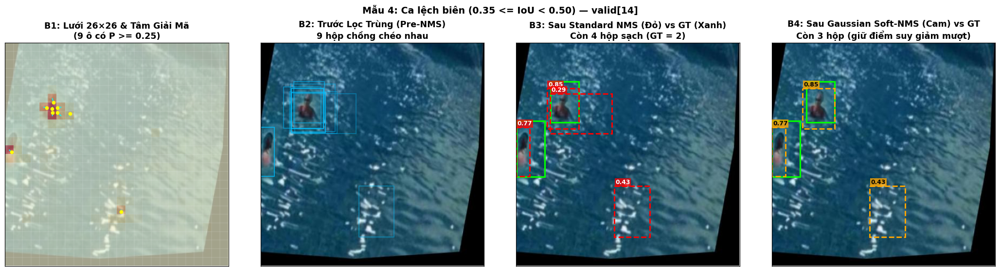

Bảng giải trình quyết định của mạng trên valid[14] (Standard NMS, score_thr=0.25):
  #Box   | Score   | Tọa độ Pixel [x1, y1, x2, y2]  | IoU cao nhất với GT  | Phân loại quyết định
  --------------------------------------------------------------------------------------------
  #0     | 0.851   | [ 57.4,  85.3, 116.6, 160.5]   | 0.644 (GT #0)        | TRUE POSITIVE (Khớp GT #0)
  #1     | 0.770   | [  0.0, 157.9,  25.4, 249.4]   | 0.417 (GT #1)        | LỆCH BIÊN / DƯ HỘP quanh GT #1 (0.25<=IoU<0.5)
  #2     | 0.435   | [182.6, 267.2, 248.5, 362.1]   | 0.000 (GT #0)        | FALSE POSITIVE (Báo nhầm vùng nền/bọt sóng)
  #3     | 0.291   | [ 63.3,  94.8, 177.8, 169.4]   | 0.289 (GT #0)        | LỆCH BIÊN / DƯ HỘP quanh GT #0 (0.25<=IoU<0.5)

In [5]:
def decode_pre_nms_candidates(raw_single: torch.Tensor, score_thr: float = 0.25):
    """Trích xuất toàn bộ các hộp ứng viên vượt ngưỡng TRƯỚC KHI chạy NMS để quan sát chùm hộp trùng."""
    scores_grid = torch.sigmoid(raw_single[0])      # [26, 26]
    box_sig = torch.sigmoid(raw_single[1:5])        # [4, 26, 26]
    gy, gx = torch.meshgrid(torch.arange(26.0), torch.arange(26.0), indexing="ij")
    cx = (gx + box_sig[0]) / 26.0
    cy = (gy + box_sig[1]) / 26.0
    bw, bh = box_sig[2], box_sig[3]

    keep = scores_grid >= score_thr
    gy_k, gx_k = torch.where(keep)
    sc_k = scores_grid[keep].numpy()
    x1 = (cx[keep] - 0.5 * bw[keep]).clamp(0, 1).numpy()
    y1 = (cy[keep] - 0.5 * bh[keep]).clamp(0, 1).numpy()
    x2 = (cx[keep] + 0.5 * bw[keep]).clamp(0, 1).numpy()
    y2 = (cy[keep] + 0.5 * bh[keep]).clamp(0, 1).numpy()
    boxes_k = np.stack([x1, y1, x2, y2], axis=-1)
    centers_k = np.stack([cx[keep].numpy(), cy[keep].numpy()], axis=-1)
    cells_k = np.stack([gx_k.numpy(), gy_k.numpy()], axis=-1)
    return boxes_k, sc_k, centers_k, cells_k


def visualize_decision_pipeline(ds_idx: int, title_prefix: str = "", score_thr: float = 0.25):
    img_t, tgt_yolo = valid_ds[ds_idx]
    img_np = img_t.permute(1, 2, 0).numpy()
    gt_boxes = targets_yolo_to_xyxy([tgt_yolo])[0]["boxes"]

    with torch.no_grad():
        raw_batch = model(img_t.unsqueeze(0).to(device))
        raw_cpu = raw_batch.detach().cpu()[0]
        post_nms = decode_stage1_outputs(raw_batch, score_thr=score_thr, nms_iou_thr=0.5, nms_type="nms")[0]
        post_soft = decode_stage1_outputs(raw_batch, score_thr=score_thr, soft_nms_sigma=0.5, nms_type="soft_nms")[0]

    pre_boxes, pre_scores, pre_centers, pre_cells = decode_pre_nms_candidates(raw_cpu, score_thr=score_thr)
    obj_grid = torch.sigmoid(raw_cpu[0]).numpy()

    fig, axes = plt.subplots(1, 4, figsize=(20, 5.2), constrained_layout=True)

    # 1. Lưới 26x26 + các ô vượt ngưỡng + vector dịch tâm
    ax0 = axes[0]
    ax0.imshow(img_np, alpha=0.65)
    ax0.imshow(obj_grid, cmap="YlOrRd", vmin=0.0, vmax=1.0, alpha=0.45, extent=(0, 416, 416, 0), interpolation="nearest")
    for g in range(0, 417, 16):
        ax0.axhline(g, color="white", lw=0.3, alpha=0.35)
        ax0.axvline(g, color="white", lw=0.3, alpha=0.35)
    for (gx_i, gy_i), (cx_i, cy_i) in zip(pre_cells, pre_centers):
        cell_cx, cell_cy = (gx_i + 0.5) * 16.0, (gy_i + 0.5) * 16.0
        ax0.plot([cell_cx, cx_i * 416], [cell_cy, cy_i * 416], color="cyan", lw=1.2)
        ax0.scatter([cx_i * 416], [cy_i * 416], color="yellow", s=18, zorder=5)
    ax0.set_title(f"B1: Lưới 26×26 & Tâm Giải Mã\n({len(pre_scores)} ô có P >= {score_thr})", fontweight="bold")

    # 2. Trước NMS: toàn bộ chùm hộp thô
    ax1 = axes[1]
    ax1.imshow(img_np)
    for (x1, y1, x2, y2), sc in zip(pre_boxes, pre_scores):
        ax1.add_patch(
            patches.Rectangle(
                (x1 * 416, y1 * 416), (x2 - x1) * 416, (y2 - y1) * 416,
                linewidth=1.3, edgecolor="deepskyblue", facecolor="none", alpha=float(np.clip(sc, 0.35, 1.0))
            )
        )
    ax1.set_title(f"B2: Trước Lọc Trùng (Pre-NMS)\n{len(pre_boxes)} hộp chồng chéo nhau", fontweight="bold")

    # 3. Sau Standard NMS + đối chiếu GT
    ax2 = axes[2]
    ax2.imshow(img_np)
    for x1, y1, x2, y2 in gt_boxes:
        ax2.add_patch(patches.Rectangle((x1 * 416, y1 * 416), (x2 - x1) * 416, (y2 - y1) * 416, lw=2.2, edgecolor="lime", facecolor="none"))
    for (x1, y1, x2, y2), sc in zip(post_nms["boxes"], post_nms["scores"]):
        ax2.add_patch(patches.Rectangle((x1 * 416, y1 * 416), (x2 - x1) * 416, (y2 - y1) * 416, lw=2.0, edgecolor="red", linestyle="--", facecolor="none"))
        ax2.text(x1 * 416 + 2, max(12, y1 * 416 - 4), f"{sc:.2f}", color="white", fontsize=8.5, fontweight="bold", bbox=dict(facecolor="red", alpha=0.75, pad=1.2, edgecolor="none"))
    ax2.set_title(f"B3: Sau Standard NMS (Đỏ) vs GT (Xanh)\nCòn {len(post_nms['boxes'])} hộp sạch (GT = {len(gt_boxes)})", fontweight="bold")

    # 4. Sau Gaussian Soft-NMS + đối chiếu GT
    ax3 = axes[3]
    ax3.imshow(img_np)
    for x1, y1, x2, y2 in gt_boxes:
        ax3.add_patch(patches.Rectangle((x1 * 416, y1 * 416), (x2 - x1) * 416, (y2 - y1) * 416, lw=2.2, edgecolor="lime", facecolor="none"))
    for (x1, y1, x2, y2), sc in zip(post_soft["boxes"], post_soft["scores"]):
        ax3.add_patch(patches.Rectangle((x1 * 416, y1 * 416), (x2 - x1) * 416, (y2 - y1) * 416, lw=2.0, edgecolor="orange", linestyle="--", facecolor="none"))
        ax3.text(x1 * 416 + 2, max(12, y1 * 416 - 4), f"{sc:.2f}", color="black", fontsize=8.5, fontweight="bold", bbox=dict(facecolor="orange", alpha=0.80, pad=1.2, edgecolor="none"))
    ax3.set_title(f"B4: Sau Gaussian Soft-NMS (Cam) vs GT\nCòn {len(post_soft['boxes'])} hộp (giữ điểm suy giảm mượt)", fontweight="bold")

    for ax in axes:
        ax.set_xlim(0, 416)
        ax.set_ylim(416, 0)
        ax.set_xticks([])
        ax.set_yticks([])

    plt.suptitle(f"{title_prefix} — valid[{ds_idx}]", fontsize=13, fontweight="bold")
    plt.show()

    # In bảng giải trình từng hộp dự đoán của Standard NMS
    ious = box_iou_xyxy(post_nms["boxes"], gt_boxes) if (len(post_nms["boxes"]) and len(gt_boxes)) else np.zeros((len(post_nms["boxes"]), len(gt_boxes)))
    print(f"Bảng giải trình quyết định của mạng trên valid[{ds_idx}] (Standard NMS, score_thr={score_thr}):")
    print(f"  {'#Box':<6} | {'Score':<7} | {'Tọa độ Pixel [x1, y1, x2, y2]':<30} | {'IoU cao nhất với GT':<20} | {'Phân loại quyết định'}")
    print("  " + "-" * 92)
    used_gt = set()
    for i, ((x1, y1, x2, y2), sc) in enumerate(zip(post_nms["boxes"], post_nms["scores"])):
        px_str = f"[{x1*416:5.1f}, {y1*416:5.1f}, {x2*416:5.1f}, {y2*416:5.1f}]"
        if len(gt_boxes):
            best_j = int(ious[i].argmax())
            best_iou = float(ious[i, best_j])
            if best_iou >= 0.50 and best_j not in used_gt:
                used_gt.add(best_j)
                verdict = f"TRUE POSITIVE (Khớp GT #{best_j})"
            elif best_iou >= 0.25:
                verdict = f"LỆCH BIÊN / DƯ HỘP quanh GT #{best_j} (0.25<=IoU<0.5)"
            else:
                verdict = "FALSE POSITIVE (Báo nhầm vùng nền/bọt sóng)"
            iou_str = f"{best_iou:.3f} (GT #{best_j})"
        else:
            iou_str = "0.000 (Không có GT)"
            verdict = "FALSE POSITIVE"
        print(f"  #{i:<5} | {sc:<7.3f} | {px_str:<30} | {iou_str:<20} | {verdict}")
    print()


# Minh họa chi tiết cả 4 mẫu đại diện
for case_key, ds_idx in SAMPLE_CASES.items():
    visualize_decision_pipeline(ds_idx, title_prefix=CASE_LABELS[case_key], score_thr=0.25)

## 5. Ô Thử Nghiệm Tương Tác: Đổi Chỉ Số Ảnh Hoặc Ngưỡng `score_thr` Tùy Ý

Bạn chỉ cần đổi giá trị `MY_SAMPLE_IDX` (từ `0` đến `1854` trên `valid`) hoặc hạ/nâng `MY_SCORE_THR` (ví dụ `0.15`, `0.25`, `0.40`) rồi bấm **Run Cell** để kiểm tra bất kỳ khung hình nào trong bể bơi!

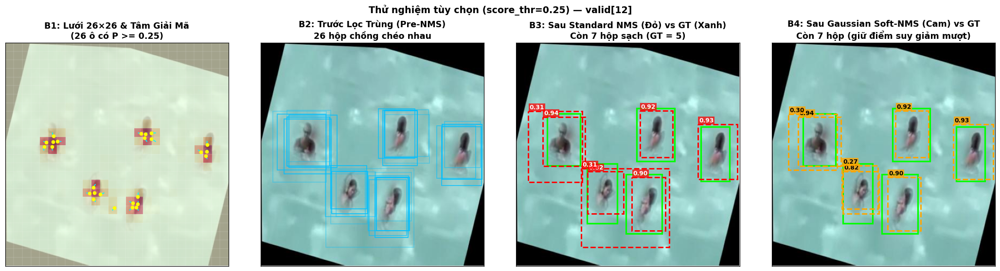

Bảng giải trình quyết định của mạng trên valid[12] (Standard NMS, score_thr=0.25):
  #Box   | Score   | Tọa độ Pixel [x1, y1, x2, y2]  | IoU cao nhất với GT  | Phân loại quyết định
  --------------------------------------------------------------------------------------------
  #0     | 0.945   | [ 49.3, 138.3, 128.5, 230.2]   | 0.722 (GT #0)        | TRUE POSITIVE (Khớp GT #0)
  #1     | 0.927   | [338.2, 151.7, 412.0, 254.2]   | 0.670 (GT #2)        | TRUE POSITIVE (Khớp GT #2)
  #2     | 0.923   | [230.3, 126.6, 291.5, 213.3]   | 0.762 (GT #1)        | TRUE POSITIVE (Khớp GT #1)
  #3     | 0.898   | [215.5, 251.1, 277.2, 350.1]   | 0.692 (GT #4)        | TRUE POSITIVE (Khớp GT #4)
  #4     | 0.825   | [132.7, 239.8, 199.7, 318.7]   | 0.611 (GT #3)        | TRUE POSITIVE (Khớp GT #3)
  #5     | 0.312   | [121.1, 234.6, 285.3, 381.2]   | 0.309 (GT #4)        | LỆCH BIÊN / DƯ HỘP quanh GT #4 (0.25<=IoU<0.5)
  #6     | 0.310   | [ 22.4, 127.3, 122.8, 259.6]   | 0.448 (GT #0)        | LỆC

In [6]:
# ---> THAY ĐỔI 2 THAM SỐ DƯỚI ĐÂY ĐỂ THỬ NGHIỆM <---
MY_SAMPLE_IDX = 12     # Chọn bất kỳ số nào từ 0 đến len(valid_ds) - 1 (0 .. 1854)
MY_SCORE_THR = 0.25    # Thử đổi sang 0.15 (ưu tiên không sót người) hoặc 0.40 (ưu tiên ít box dư)

visualize_decision_pipeline(
    MY_SAMPLE_IDX,
    title_prefix=f"Thử nghiệm tùy chọn (score_thr={MY_SCORE_THR})",
    score_thr=MY_SCORE_THR,
)

## 6. Theo Dõi Trên 2 Khung Hình Liên Tiếp Trong Cùng Một Video (`Frame t → Frame t+1`)

Nhờ `clean Group Split` gom trọn các khung hình của cùng một video gốc vào chung một tập, ta lấy trực tiếp **2 cặp khung hình liên tiếp (cùng góc máy, không bị lật ngược)** trên tập `valid` để quan sát:
1. **`drowning54.mp4` (`frame 12 → frame 13`, `valid[953] → valid[959]`):** Tình huống 1 người dưới nước — đặc trưng `head_refine` và hộp dự đoán bám sát mục tiêu mượt mà qua 2 frame (`1 → 1` hộp, `0` báo giả).
2. **`drowning53.mp4` (`frame 7 → frame 8`, `valid[1752] → valid[919]`):** Tình huống hồ bơi có **3 người cùng lúc** — minh họa cách **bộ ghép cặp liên khung hình (`IoU / Byte-style Association`)** nối đúng `Track ID #0, #1, #2...` từ `Frame t` sang `Frame t+1`, đồng thời tách biệt các hộp nhiễu sóng chỉ nháy lên ở 1 frame đơn lẻ!

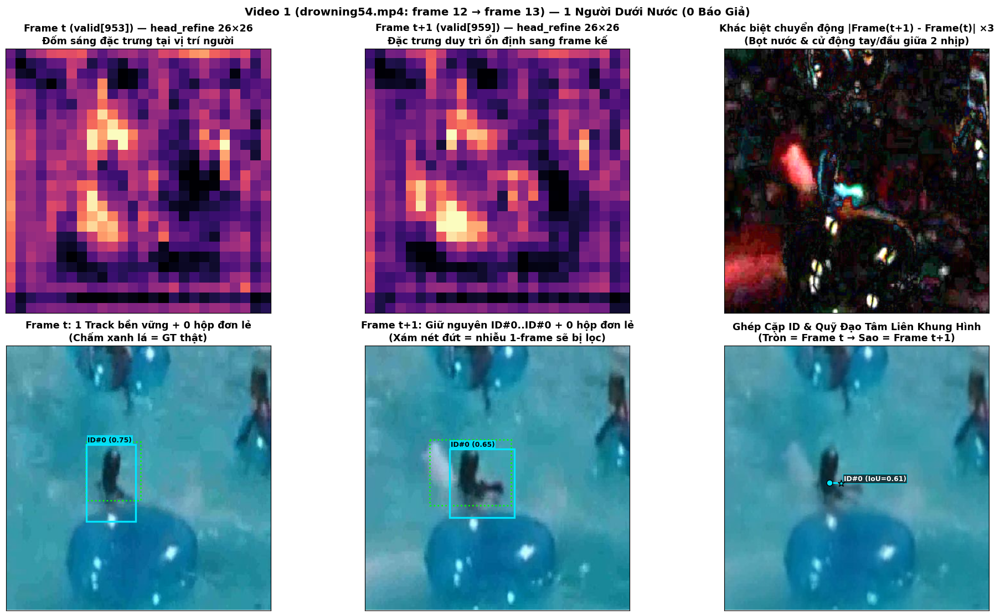

Bảng theo dõi đối tượng liên khung hình — Video 1 (drowning54.mp4: frame 12 → frame 13) — 1 Người Dưới Nước (0 Báo Giả):
  Track ID  | Score (t -> t+1)   | Temporal IoU   | Dịch tâm (px)   | Khớp GT ở Frame t+1
  --------------------------------------------------------------------------------------
  ID #0     | 0.75  -->  0.65    | 0.608          | 18.1            | Người thật (IoU với GT = 0.55)

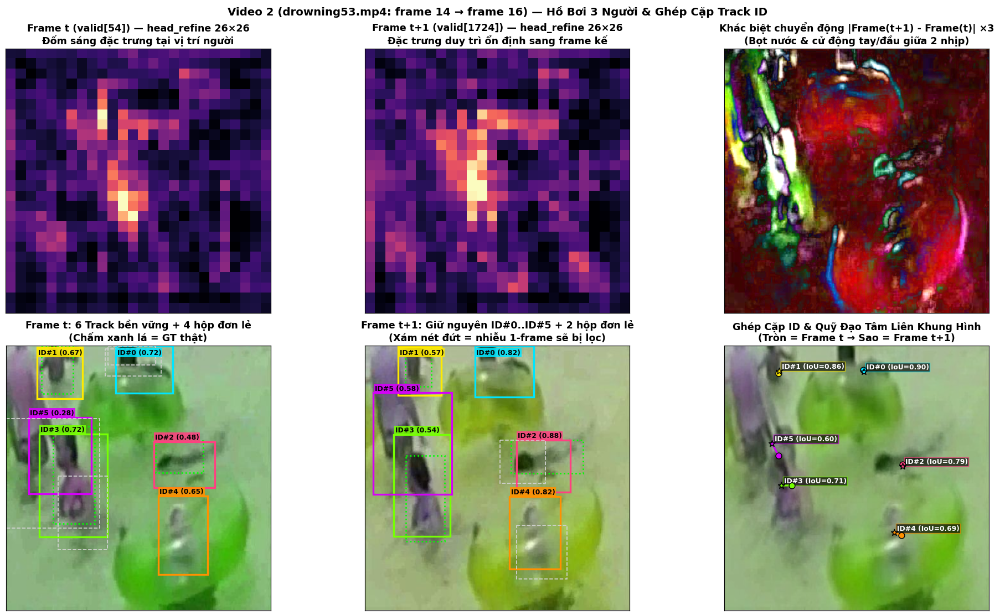

Bảng theo dõi đối tượng liên khung hình — Video 2 (drowning53.mp4: frame 14 → frame 16) — Hồ Bơi 3 Người & Ghép Cặp Track ID:
  Track ID  | Score (t -> t+1)   | Temporal IoU   | Dịch tâm (px)   | Khớp GT ở Frame t+1
  --------------------------------------------------------------------------------------
  ID #0     | 0.72  -->  0.82    | 0.898          | 3.0             | Vùng bọt sóng lặp lại (IoU GT = 0.00)
  ID #1     | 0.67  -->  0.57    | 0.861          | 3.5             | Người thật (IoU với GT = 0.50)
  ID #2     | 0.48  -->  0.88    | 0.791          | 2.3             | Người thật (IoU với GT = 0.52)
  ID #3     | 0.72  -->  0.54    | 0.706          | 16.4            | Người thật (IoU với GT = 0.53)
  ID #4     | 0.65  -->  0.82    | 0.694          | 12.2            | Vùng bọt sóng lặp lại (IoU GT = 0.00)
  ID #5     | 0.28  -->  0.58    | 0.604          | 21.7            | Vùng bọt sóng lặp lại (IoU GT = 0.15)
  -> Đã loại bỏ 4 hộp nháy lẻ ở Frame t và 2 hộp nháy lẻ ở Frame t+1

In [7]:
def associate_two_frames_iou(boxes_t, scores_t, boxes_t1, scores_t1, iou_match_thr: float = 0.30):
    """
    Minh họa ghép cặp ID liên khung hình (kiểu IoU / ByteTrack thu gọn) giữa Frame t và Frame t+1:
    Trả về danh sách các cặp khớp (idx_t, idx_t1, temporal_iou) và các hộp lẻ không khớp.
    """
    if len(boxes_t) == 0 or len(boxes_t1) == 0:
        return [], list(range(len(boxes_t))), list(range(len(boxes_t1)))

    ious = box_iou_xyxy(boxes_t, boxes_t1)
    matched_pairs = []
    used_t, used_t1 = set(), set()

    # Ghép tham lam theo điểm kết hợp (IoU liên-frame + độ tự tin)
    flat_order = np.argsort(-ious.ravel())
    for flat_idx in flat_order:
        i = int(flat_idx // len(boxes_t1))
        j = int(flat_idx % len(boxes_t1))
        if i in used_t or j in used_t1:
            continue
        if ious[i, j] < iou_match_thr:
            break
        used_t.add(i)
        used_t1.add(j)
        matched_pairs.append((i, j, float(ious[i, j])))

    unmatched_t = [i for i in range(len(boxes_t)) if i not in used_t]
    unmatched_t1 = [j for j in range(len(boxes_t1)) if j not in used_t1]
    return matched_pairs, unmatched_t, unmatched_t1


def inspect_consecutive_video_frames(idx_t: int, idx_t1: int, video_title: str, score_thr: float = 0.25):
    img_t, tgt_t = valid_ds[idx_t]
    img_t1, tgt_t1 = valid_ds[idx_t1]
    np_t = img_t.permute(1, 2, 0).numpy()
    np_t1 = img_t1.permute(1, 2, 0).numpy()
    gt_t = targets_yolo_to_xyxy([tgt_t])[0]["boxes"]
    gt_t1 = targets_yolo_to_xyxy([tgt_t1])[0]["boxes"]

    feats_t, raw_t = extract_features_and_raw_output(img_t)
    feats_t1, raw_t1 = extract_features_and_raw_output(img_t1)

    with torch.no_grad():
        dec = decode_stage1_outputs(torch.stack([raw_t, raw_t1]).to(device), score_thr=score_thr, nms_type="nms")
    pred_t, pred_t1 = dec[0], dec[1]

    matches, un_t, un_t1 = associate_two_frames_iou(
        pred_t["boxes"], pred_t["scores"], pred_t1["boxes"], pred_t1["scores"], iou_match_thr=0.30
    )

    track_colors = ["#00e5ff", "#ffea00", "#ff4081", "#76ff03", "#ff9100", "#d500f9", "#1de9b6", "#ff1744"]
    fig, axes = plt.subplots(2, 3, figsize=(18.5, 10.5), constrained_layout=True)

    # --- HÀNG 1: Đặc trưng head_refine (RF ~207px) & Bản đồ xác suất P(person) của 2 frame ---
    e_t = normalize_map(torch.linalg.vector_norm(feats_t["HeadRefine_26x26"], ord=2, dim=0).numpy())
    e_t1 = normalize_map(torch.linalg.vector_norm(feats_t1["HeadRefine_26x26"], ord=2, dim=0).numpy())
    diff_rgb = np.clip(np.abs(np_t1 - np_t) * 3.0, 0.0, 1.0)

    axes[0, 0].imshow(e_t, cmap="magma")
    axes[0, 0].set_title(f"Frame t (valid[{idx_t}]) — head_refine 26×26\nĐốm sáng đặc trưng tại vị trí người", fontweight="bold")

    axes[0, 1].imshow(e_t1, cmap="magma")
    axes[0, 1].set_title(f"Frame t+1 (valid[{idx_t1}]) — head_refine 26×26\nĐặc trưng duy trì ổn định sang frame kế", fontweight="bold")

    axes[0, 2].imshow(diff_rgb)
    axes[0, 2].set_title("Khác biệt chuyển động |Frame(t+1) - Frame(t)| ×3\n(Bọt nước & cử động tay/đầu giữa 2 nhịp)", fontweight="bold")

    # --- HÀNG 2: Hộp dự đoán gắn Track ID ở Frame t, Frame t+1 & Vector quỹ đạo ---
    axes[1, 0].imshow(np_t)
    for x1, y1, x2, y2 in gt_t:
        axes[1, 0].add_patch(patches.Rectangle((x1*416, y1*416), (x2-x1)*416, (y2-y1)*416, lw=1.8, edgecolor="lime", linestyle=":", facecolor="none"))

    axes[1, 1].imshow(np_t1)
    for x1, y1, x2, y2 in gt_t1:
        axes[1, 1].add_patch(patches.Rectangle((x1*416, y1*416), (x2-x1)*416, (y2-y1)*416, lw=1.8, edgecolor="lime", linestyle=":", facecolor="none"))

    axes[1, 2].imshow(0.5 * np_t + 0.5 * np_t1)

    # Vẽ các Track giữ bền vững qua cả 2 frame
    for tid, (i, j, tiou) in enumerate(matches):
        col = track_colors[tid % len(track_colors)]
        bx_a, sc_a = pred_t["boxes"][i], pred_t["scores"][i]
        bx_b, sc_b = pred_t1["boxes"][j], pred_t1["scores"][j]

        axes[1, 0].add_patch(patches.Rectangle((bx_a[0]*416, bx_a[1]*416), (bx_a[2]-bx_a[0])*416, (bx_a[3]-bx_a[1])*416, lw=2.3, edgecolor=col, facecolor="none"))
        axes[1, 0].text(bx_a[0]*416 + 2, max(13, bx_a[1]*416 - 4), f"ID#{tid} ({sc_a:.2f})", color="black", fontsize=8.5, fontweight="bold", bbox=dict(facecolor=col, alpha=0.88, pad=1.2, edgecolor="none"))

        axes[1, 1].add_patch(patches.Rectangle((bx_b[0]*416, bx_b[1]*416), (bx_b[2]-bx_b[0])*416, (bx_b[3]-bx_b[1])*416, lw=2.3, edgecolor=col, facecolor="none"))
        axes[1, 1].text(bx_b[0]*416 + 2, max(13, bx_b[1]*416 - 4), f"ID#{tid} ({sc_b:.2f})", color="black", fontsize=8.5, fontweight="bold", bbox=dict(facecolor=col, alpha=0.88, pad=1.2, edgecolor="none"))

        cxa, cya = 0.5 * (bx_a[0] + bx_a[2]) * 416, 0.5 * (bx_a[1] + bx_a[3]) * 416
        cxb, cyb = 0.5 * (bx_b[0] + bx_b[2]) * 416, 0.5 * (bx_b[1] + bx_b[3]) * 416
        axes[1, 2].scatter([cxa], [cya], color=col, s=55, marker="o", edgecolor="black", zorder=5)
        axes[1, 2].scatter([cxb], [cyb], color=col, s=70, marker="*", edgecolor="black", zorder=6)
        axes[1, 2].plot([cxa, cxb], [cya, cyb], color=col, lw=2.2, zorder=4)
        axes[1, 2].text(cxb + 4, cyb - 4, f"ID#{tid} (IoU={tiou:.2f})", color="white", fontsize=8.5, fontweight="bold", bbox=dict(facecolor="black", alpha=0.65, pad=1.2, edgecolor=col))

    # Vẽ mờ bằng nét đứt xám các hộp nhiễu lẻ chỉ xuất hiện ở 1 frame đơn độc
    for i in un_t:
        bx = pred_t["boxes"][i]
        axes[1, 0].add_patch(patches.Rectangle((bx[0]*416, bx[1]*416), (bx[2]-bx[0])*416, (bx[3]-bx[1])*416, lw=1.2, edgecolor="lightgray", linestyle="--", facecolor="none"))
    for j in un_t1:
        bx = pred_t1["boxes"][j]
        axes[1, 1].add_patch(patches.Rectangle((bx[0]*416, bx[1]*416), (bx[2]-bx[0])*416, (bx[3]-bx[1])*416, lw=1.2, edgecolor="lightgray", linestyle="--", facecolor="none"))

    axes[1, 0].set_title(f"Frame t: {len(matches)} Track bền vững + {len(un_t)} hộp đơn lẻ\n(Chấm xanh lá = GT thật)", fontweight="bold")
    axes[1, 1].set_title(f"Frame t+1: Giữ nguyên ID#{0}..ID#{max(0, len(matches)-1)} + {len(un_t1)} hộp đơn lẻ\n(Xám nét đứt = nhiễu 1-frame sẽ bị lọc)", fontweight="bold")
    axes[1, 2].set_title("Ghép Cặp ID & Quỹ Đạo Tâm Liên Khung Hình\n(Tròn = Frame t → Sao = Frame t+1)", fontweight="bold")

    for r in range(2):
        for c in range(3):
            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])

    plt.suptitle(video_title, fontsize=13.5, fontweight="bold")
    plt.show()

    # In bảng theo dõi ID qua 2 frame
    ious_gt_t1 = box_iou_xyxy(pred_t1["boxes"], gt_t1) if (len(pred_t1["boxes"]) and len(gt_t1)) else np.zeros((len(pred_t1["boxes"]), len(gt_t1)))
    print(f"Bảng theo dõi đối tượng liên khung hình — {video_title}:")
    print(f"  {'Track ID':<9} | {'Score (t -> t+1)':<18} | {'Temporal IoU':<14} | {'Dịch tâm (px)':<15} | {'Khớp GT ở Frame t+1'}")
    print("  " + "-" * 86)
    for tid, (i, j, tiou) in enumerate(matches):
        bx_a, bx_b = pred_t["boxes"][i], pred_t1["boxes"][j]
        dx = 0.5 * ((bx_b[0] + bx_b[2]) - (bx_a[0] + bx_a[2])) * 416
        dy = 0.5 * ((bx_b[1] + bx_b[3]) - (bx_a[1] + bx_a[3])) * 416
        shift_px = float(np.hypot(dx, dy))
        gt_iou = float(ious_gt_t1[j].max()) if len(gt_t1) else 0.0
        status = f"Người thật (IoU với GT = {gt_iou:.2f})" if gt_iou >= 0.50 else (f" Sát biên người (IoU GT = {gt_iou:.2f})" if gt_iou >= 0.25 else f"Vùng bọt sóng lặp lại (IoU GT = {gt_iou:.2f})")
        print(f"  ID #{tid:<5} | {pred_t['scores'][i]:.2f}  -->  {pred_t1['scores'][j]:.2f}    | {tiou:<14.3f} | {shift_px:<15.1f} | {status}")
    if un_t or un_t1:
        print(f"  -> Đã loại bỏ {len(un_t)} hộp nháy lẻ ở Frame t và {len(un_t1)} hộp nháy lẻ ở Frame t+1 (không duy trì qua 2 frame).")
    print()


# Cặp Video 1: 1 người dưới nước (drowning54.mp4: frame 12 -> frame 13)
inspect_consecutive_video_frames(
    idx_t=953,
    idx_t1=959,
    video_title="Video 1 (drowning54.mp4: frame 12 → frame 13) — 1 Người Dưới Nước (0 Báo Giả)",
    score_thr=0.25,
)

# Cặp Video 2: Hồ bơi 3 người cùng lúc (drowning53.mp4: frame 14 -> frame 16)
inspect_consecutive_video_frames(
    idx_t=54,
    idx_t1=1724,
    video_title="Video 2 (drowning53.mp4: frame 14 → frame 16) — Hồ Bơi 3 Người & Ghép Cặp Track ID",
    score_thr=0.25,
)